<a href="https://colab.research.google.com/github/anderson-perez/DEC0014/blob/main/Aula_15_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise dos modelos KNN, Árvore de Decisão e Regressão Logística para prever a falha de uma máquina.

O dataset utilizado está disponível no Kaggle. Acesso: https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification?resource=download

In [ ]:
import pandas as pd

In [ ]:
dados = pd.read_csv('/content/predictive_maintenance.csv')

In [ ]:
dados.head(3)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure


In [ ]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB


In [ ]:
dados.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [ ]:
dados.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Failure Type,0


In [ ]:
colunas = dados.columns.to_list()

In [ ]:
colunas

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Target',
 'Failure Type']

In [ ]:
dados = dados.drop(['UDI', 'Product ID','Failure Type'], axis=1)

In [ ]:
dados.head(3)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0


In [ ]:
dados.shape

(10000, 7)

In [ ]:
dados['Type'].value_counts()

,count
Type,
L,6000
M,2997
H,1003


In [ ]:
dados['Target'].value_counts()

,count
Target,
0,9661
1,339


In [ ]:
dd = pd.get_dummies(dados)

In [ ]:
dd.head(1)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,False,False,True


In [ ]:
dd.shape

(10000, 9)

In [ ]:
# Separar features de targets
X = dd.drop(['Target'], axis=1)
y = dd['Target']

In [ ]:
X.shape, y.shape

((10000, 8), (10000,))

In [ ]:
# Separar dados para treino e para teste
from sklearn.model_selection import train_test_split

In [ ]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, random_state=42)

In [ ]:
X_treino.shape, X_teste.shape

((7500, 8), (2500, 8))

In [ ]:
# Instanciar os modelos
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [ ]:
c_linear = LogisticRegression()
c_knn = KNeighborsClassifier()
c_arvore = DecisionTreeClassifier()

In [ ]:
c_linear.fit(X_treino, y_treino)
c_knn.fit(X_treino, y_treino)
c_arvore.fit(X_treino, y_treino)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


DecisionTreeClassifier()

In [ ]:
# Matriz de confusão
y = [1, 0, 1, 1, 0]
y_pred = [1, 1, 0, 1, 0]

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
print(confusion_matrix(y, y_pred))

[[1 1]
 [1 2]]


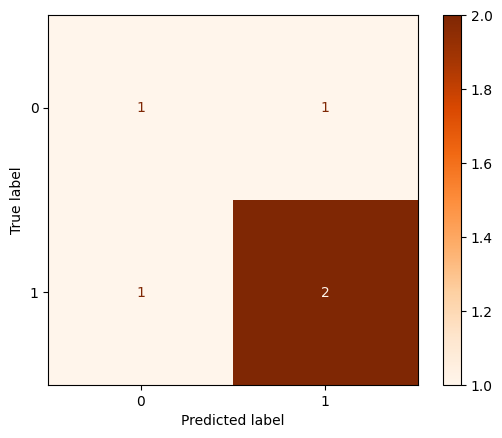

In [ ]:
ConfusionMatrixDisplay.from_predictions(y, y_pred, cmap='Oranges')

In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score, classification_report, accuracy_score

In [ ]:
print(f'Linear: {accuracy_score(y_teste, c_linear.predict(X_teste))}')
print(f'KNN: {accuracy_score(y_teste, c_knn.predict(X_teste))}')
print(f'Árvore: {accuracy_score(y_teste, c_arvore.predict(X_teste))}')


Linear: 0.9752
KNN: 0.9724
Árvore: 0.9796


In [ ]:
X_teste.shape

(2500, 8)

In [ ]:
print(classification_report(y_teste, c_linear.predict(X_teste)))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2428
           1       0.67      0.28      0.39        72

    accuracy                           0.98      2500
   macro avg       0.82      0.64      0.69      2500
weighted avg       0.97      0.98      0.97      2500

